# Custom geometries

Nothing in the planner is specific to psic. A geometry is a list of axes; the
modes, the counting of what must be held and the closed-form steps all follow
from it. Two examples: one in xrayutilities' syntax (checked against
xrayutilities' own forward model), and a kappa diffractometer, whose kappa
axis is tilted - something no Euler-angle formula covers.

In [1]:
import sys, os, logging, warnings
sys.path.insert(0, os.path.abspath("../src"))      # hklforge from this repository
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hklforge import Diffractometer, Geometry, ModeError, Degenerate
from hklforge.lattice import b_matrix
from hklforge.draw import draw, draw_circles
logging.getLogger("diffcalc").setLevel(logging.ERROR)
pd.set_option("display.precision", 3)
%matplotlib inline

## xrayutilities syntax
A 2+2 surface diffractometer: sample omega (about z−, outermost) and a tilt (about y+);
detector nu (x+) and delta (z−), beam along y.

Geometry('2+2': sample [om(z-), tilt(y+)] | detector [nu(x+), delta(z-)] | beam (y+))


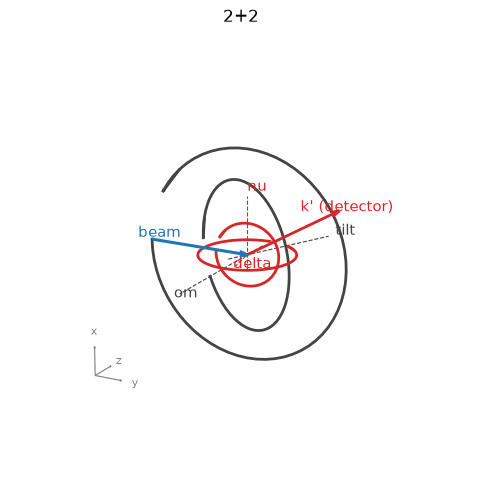

In [2]:
g = Geometry.from_xrayutilities(["z-", "y+"], ["x+", "z-"], r_i=(0, 1, 0),
                                 sample_names=["om", "tilt"], detector_names=["nu", "delta"], name="2+2")
print(g)
draw_circles(g, {"om": 20, "tilt": 10, "nu": 10, "delta": 30});

In [3]:
import xrayutilities as xu
qc = xu.experiment.QConversion(["z-", "y+"], ["x+", "z-"], (0, 1, 0))
lam = xu.en2lam(10000)
rng = np.random.default_rng(0)
worst = 0
for _ in range(200):
    a = dict(zip(g.names, rng.uniform(-150, 150, 4)))
    worst = max(worst, np.abs(g.q_phi(a, 2 * np.pi / lam) - np.ravel(qc(*[a[n] for n in g.names], wl=lam))).max())
print(f"forward model vs xrayutilities QConversion, 200 random positions: max |dQ| = {worst:.1e} 1/A")

forward model vs xrayutilities QConversion, 200 random positions: max |dQ| = 2.7e-15 1/A


Four circles: one thing to hold. With the incidence angle held (the usual surface-diffraction
mode), every solution:

In [4]:
ub = b_matrix(3.905, 3.905, 3.905)              # SrTiO3, (0 0 1) surface along the tilt-free z
d = Diffractometer(g, ub, energy=10000, surface_hkl=(0, 0, 1), reference_hkl=(0, 0, 1))
m = {"betain": 0.5}
print(d.plan(m).describe())
sols = d.solve((1, 0, 0.5), m)
pd.DataFrame([s | {k: d.pseudo(s)[k] for k in ("betain", "betaout", "ttheta")} for s in sols])

2+2: betain=0.5, detector on h1  [beam_x]
  1. beam in the phi frame x = R^T b from Bragg + betain: cone_points (<= 2)
  2. sample (om, tilt) from R x = b: sp2 (<= 2)
  3. k' = b + R q / k; detector (nu, delta): sp2 (<= 2)


,om,tilt,nu,delta,betain,betaout,ttheta
0,168.798,2.575,-171.243,-161.45,0.5,8.628,20.447
1,168.798,2.575,8.757,-18.55,0.5,8.628,20.447
2,-168.798,-177.425,171.243,161.45,0.5,8.628,20.447
3,-168.798,-177.425,-8.757,18.55,0.5,8.628,20.447
4,11.202,2.575,-171.243,161.45,0.5,8.628,20.447
5,11.202,2.575,8.757,18.55,0.5,8.628,20.447
6,-11.202,-177.425,171.243,-161.45,0.5,8.628,20.447
7,-11.202,-177.425,-8.757,-18.55,0.5,8.628,20.447


Each solution through xrayutilities' forward model:

In [5]:
for s in sols:
    q_xu = np.ravel(qc(*[s[n] for n in g.names], wl=lam))
    print(np.round(np.linalg.solve(ub, q_xu), 9))

[1.  0.  0.5]
[1.  0.  0.5]
[1.  0.  0.5]
[1.  0.  0.5]
[ 1.  -0.   0.5]
[ 1.  -0.   0.5]
[ 1.  -0.   0.5]
[ 1.  -0.   0.5]


## A kappa diffractometer
Kappa four-circle (as libhkl's K4CV): komega about z−, kappa about an axis tilted by
α = 50° from z towards the beam, kphi about z−; detector tth about z−. Written as YAML:

Geometry('kappa4c': sample [komega(z-), kappa(0,-0.766,-0.643), kphi(z-)] | detector [tth(z-)] | beam (y+))


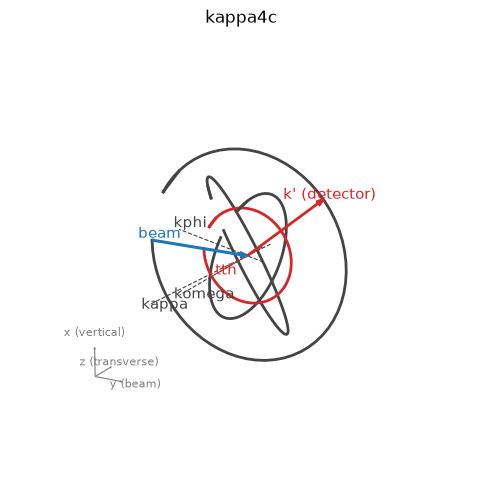

In [6]:
alpha = np.radians(50)
yaml_text = f"""
name: kappa4c
beam: y+
labels: {{x: vertical, y: beam, z: transverse}}
sample:
  - {{name: komega, axis: [0, 0, -1]}}
  - {{name: kappa,  axis: [0, {-np.sin(alpha):.12f}, {-np.cos(alpha):.12f}]}}
  - {{name: kphi,   axis: [0, 0, -1]}}
detector:
  - {{name: tth, axis: [0, 0, -1]}}
"""
k4 = Geometry.from_yaml(yaml_text)
print(k4)
draw_circles(k4, {"komega": 30, "kappa": 60, "kphi": 0, "tth": 40});

In [7]:
dk = Diffractometer(k4, b_matrix(5.431, 5.431, 5.431), energy=9000, surface_hkl=(0, 0, 1))
for m in ({"kphi": 0}, {"kappa": 30}, {"komega": 10}, {"betain": 5}):
    sols = dk.solve((2, 2, 0), m)
    print(dk.plan(m).describe())
    for s in sols:
        print("   ", {k: round(v, 4) for k, v in s.items()}, " hkl back:", np.round(dk.hkl(s), 10))

kappa4c: kphi=0.0, detector on h1  [q]
  1. Bragg on the detector (tth): b.k' = cos 2theta, projection (<= 2)
  2. Q_lab = k (k' - b); sample (komega, kappa) from R q = Q_lab: sp2 (<= 2)
    {'komega': 66.0218, 'kappa': 0.0, 'kphi': 0.0, 'tth': 42.0436}  hkl back: [2. 2. 0.]
    {'komega': 156.0218, 'kappa': -114.5352, 'kphi': 0.0, 'tth': 42.0436}  hkl back: [ 2.  2. -0.]
    {'komega': -156.0218, 'kappa': 0.0, 'kphi': 0.0, 'tth': -42.0436}  hkl back: [2. 2. 0.]
    {'komega': -66.0218, 'kappa': -114.5352, 'kphi': 0.0, 'tth': -42.0436}  hkl back: [2. 2. 0.]
kappa4c: kappa=30.0, detector on h1  [q]
  1. Bragg on the detector (tth): b.k' = cos 2theta, projection (<= 2)
  2. Q_lab = k (k' - b); sample (komega, kphi) from R q = Q_lab: sp2 (<= 2)
    {'komega': 101.2494, 'kappa': 30.0, 'kphi': -54.7724, 'tth': 42.0436}  hkl back: [2. 2. 0.]
    {'komega': -78.7506, 'kappa': 30.0, 'kphi': 125.2276, 'tth': 42.0436}  hkl back: [2. 2. 0.]
    {'komega': -120.7942, 'kappa': 30.0, 'kphi': -54.772

A kappa with α = 50° can tilt the sample by at most 2α = 100° (an Eulerian chi of ±100°),
so some reflections are out of reach with some circles held - then there are simply no solutions:

In [8]:
for h in [(1, 1, 1), (0, 0, 4), (1, 1, 3)]:
    print(h, {str(m): len(dk.solve(h, m)) for m in ({"kphi": 0}, {"kappa": 30}, {"komega": 10}, {"betain": 5})})

(1, 1, 1) {"{'kphi': 0}": 0, "{'kappa': 30}": 0, "{'komega': 10}": 2, "{'betain': 5}": 4}
(0, 0, 4) {"{'kphi': 0}": 4, "{'kappa': 30}": 0, "{'komega': 10}": 0, "{'betain': 5}": 0}
(1, 1, 3) {"{'kphi': 0}": 0, "{'kappa': 30}": 0, "{'komega': 10}": 0, "{'betain': 5}": 4}


With kappa held, komega and kphi rotate about the same axis whenever kappa = 0 - then the
solutions form a continuum and that is said, rather than an arbitrary answer returned:

In [9]:
try:
    dk.solve((1, 1, 1), {"kappa": 0})
except Degenerate as e:
    print("Degenerate:", e)

Degenerate: the two directions are parallel (free: komega, kphi, tth; held: kappa=0)
